[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/07.%20Support%20Vector%20Machines%20and%20Kernel%20Methods/ch07_svm_kernel_methods.ipynb)

# Chapter 7: Support Vector Machines and Kernel Methods

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 7, pp. 180–209

**What you will learn in this chapter:**
- The idea behind support vector machines (SVMs): the maximum-margin hyperplane, support vectors and the soft margin
- How kernel functions (linear, polynomial, RBF) let a linear method draw non-linear boundaries — the kernel trick
- How to tune `C`, `gamma`, `degree` and the kernel with grid search and cross-validation
- How SVMs behave on high-dimensional ("wide") data
- How to evaluate an SVM: classification report, ROC curve and AUC
- Practical exercises: a simple SVM, a tuned SVM and decision-boundary visualisation

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Introduction to SVMs | Find the hyperplane with the widest margin; only the support vectors matter | `SVC`, `SVR` |
| Kernel functions | Compute dot products in a richer feature space without building it | `kernel='linear' / 'poly' / 'rbf'` |
| Tuning | `C` (margin vs errors), `gamma` and `degree` (kernel shape) | `GridSearchCV` |
| High-dimensional data | SVMs cope with many features, but defaults may not be enough | `make_classification`, `PCA` |
| Evaluation | Report, ROC curve, AUC | `classification_report`, `roc_curve`, `auc` |
| Practical exercises | Simple, tuned and visualised SVMs | — |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, a verification against the numbers printed in the book, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text or code is inaccurate or incomplete are flagged with **Book correction** (collected again at the end).
Missing imports in the book's snippets (`numpy`, `matplotlib`, `accuracy_score`) are added here.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)

scikit-learn version: 1.9.1
NumPy version       : 2.5.3


## 1. Introduction to SVMs

**Summary.** Support vector machines are models for **classification and regression**. They are especially effective when the number of features is large compared to the number of samples, and when classes are not easily separable in the original features.
The core idea: find the **hyperplane** that **maximises the margin** between the classes — the distance from the hyperplane to the nearest points of each class, which are called the **support vectors**. A larger margin is expected to generalise better.

> **Book correction (what a hyperplane is).** The book says "a hyperplane serves as a decision boundary – a *non-linear line (i.e., a curved line in two or more dimensions)*". That is wrong: a hyperplane is **flat** — a line in 2-D, a plane in 3-D, and in general a
> $(p-1)$-dimensional flat subspace $\{x: w^\top x+b=0\}$. SVMs get *curved* boundaries in the original space only by using a **kernel**, which makes the boundary a flat hyperplane in a (hidden) higher-dimensional space. A linear-kernel SVM has a straight boundary.

### Getting ready — the Iris dataset

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.datasets import load_iris
from sklearn.metrics import (
    accuracy_score, classification_report)
import pandas as pd

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)
print(X_train.shape, X_test.shape, "| test class counts:", np.bincount(y_test))

(105, 4) (45, 4) | test class counts: [18 12 15]


### How to do it… — classification with a linear kernel

In [3]:
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(X_train, y_train)
y_pred = svm_classifier.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

styled_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.2f}")
styled_df

Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


**Verification against the book:** Figure 7.1 shows accuracy **0.933** with per-class precision 1.000 / 0.909 / 0.875 and recall 1.000 / 0.833 / 0.933 — reproduced above ✔ (support 18 / 12 / 15).
(As in Chapter 6, the `accuracy` row's "support" of 1 is just the accuracy value 0.93 rounded by the `'{:.0f}'` format, not a sample count.)

### How to do it… — a regression with `SVR`
The book then uses an SVM for "a simple regression problem": `SVR(kernel='rbf')` fitted on the first two Iris features with the **class label (0, 1, 2) as the target**.

In [4]:
svm_regressor = SVR(kernel='rbf')
svm_regressor.fit(X_train[:, :2], y_train)
y_pred_reg = svm_regressor.predict(X_test[:, :2])

# Note: For regression,
# we typically use metrics like MSE or R-squared
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.2f}")

MSE: 0.20


**Verification against the book:** it prints `MSE: 0.20` ✔ (0.204).

> **Note.** This "regression" treats the class ids 0/1/2 as if they were numbers on a scale (class 2 is "twice" class 1), so the MSE is only a mechanical demonstration of `SVR`'s API, not a meaningful performance number. For a real regression problem see the
> Extension below (`SVR` on a continuous target). Remember that for MSE/MAE/MAPE lower is better and "how low is acceptable" is a business question.

### How it works…
SVMs find the maximum-margin hyperplane; the margin is the distance between the hyperplane and the nearest points of each class (the support vectors). Two ideas from the book:
* **Kernel functions** map the data into a higher-dimensional space where it can become linearly separable (linear, polynomial, RBF — Section 2).
* **Soft margin**: slack variables let the SVM tolerate some misclassifications, which makes it robust to outliers (the book's "rope" analogy: loosen the rope — the hyperplane and support vectors — to allow flexibility).

**Extension — look inside the model: support vectors, the weight vector, the margin.** Only the support vectors define the hyperplane; for a *linear* kernel, the decision function is exactly $w^\top x+b$.

support vectors per class: [12 12] of 100 training points  -> 24% of the data defines the model
w = [2.183 2.254]  b = -14.415
margin width = 2 / ||w|| = 0.637
decision_function == w.x + b: True
decision values on support vectors (|f| should be about 1 for those on the margin): [1.   0.34 0.99 0.55 1.   0.12 0.34 0.78]


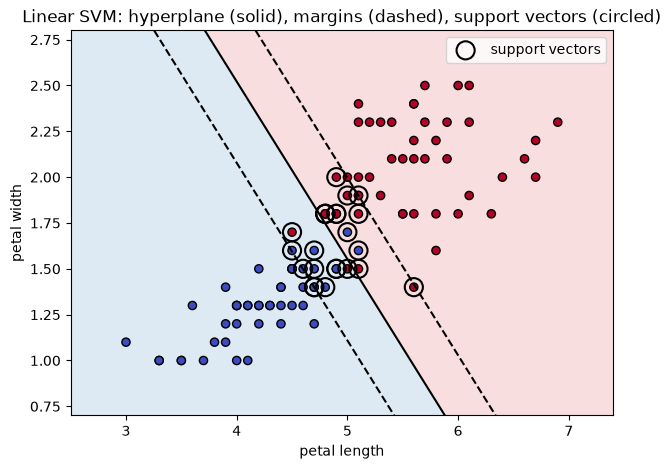

In [5]:
# a clean two-class version of Iris (versicolor vs virginica, petal features) to make the geometry visible
mask = y != 0
X2, y2 = X[mask][:, 2:4], (y[mask] == 2).astype(int)
lin = SVC(kernel="linear", C=1.0).fit(X2, y2)
w, b = lin.coef_[0], lin.intercept_[0]

print("support vectors per class:", lin.n_support_, "of", len(X2), "training points  ->", f"{lin.n_support_.sum() / len(X2):.0%} of the data defines the model")
print("w =", w.round(3), " b =", round(b, 3))
print("margin width = 2 / ||w|| =", round(2 / np.linalg.norm(w), 3))
print("decision_function == w.x + b:", np.allclose(lin.decision_function(X2), X2 @ w + b))
sv = lin.support_vectors_
print("decision values on support vectors (|f| should be about 1 for those on the margin):", np.round(np.abs(lin.decision_function(sv))[:8], 2))

xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - .5, X2[:, 0].max() + .5, 300), np.linspace(X2[:, 1].min() - .3, X2[:, 1].max() + .3, 300))
Z = lin.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, levels=[-10, 0, 10], alpha=.15, colors=["tab:blue", "tab:red"])
plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", edgecolor="k", s=35)
plt.scatter(sv[:, 0], sv[:, 1], s=170, facecolors="none", edgecolors="k", linewidths=1.5, label="support vectors")
plt.xlabel("petal length"); plt.ylabel("petal width"); plt.title("Linear SVM: hyperplane (solid), margins (dashed), support vectors (circled)"); plt.legend(); plt.show()

The solid line is the hyperplane ($f(x)=0$); the dashed lines are the margins ($f(x)=\pm1$). Points circled are the support vectors — those on or inside the margin. **Every other point could be deleted and the model would not change** — that is what makes SVMs "sparse" in the data.

**Extension — the soft margin in action: the effect of `C`.** Small `C` = wide margin, many margin violations tolerated (more support vectors, simpler model); large `C` = narrow margin, few violations tolerated.

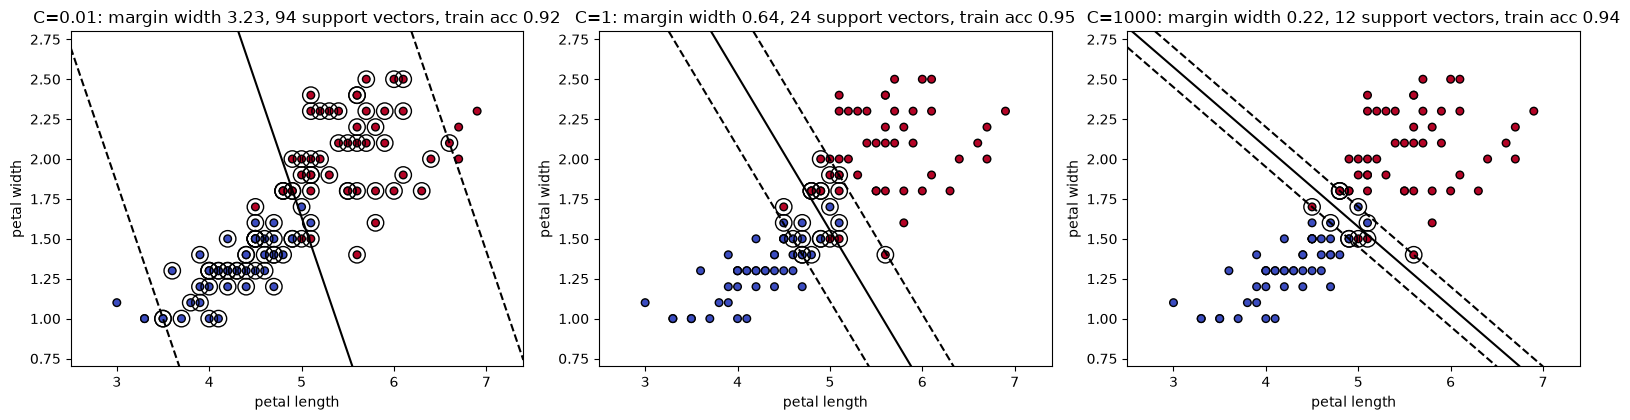

In [6]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, Cval in zip(axes, (0.01, 1, 1000)):
    m = SVC(kernel="linear", C=Cval).fit(X2, y2)
    Z = m.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", edgecolor="k", s=30)
    ax.scatter(m.support_vectors_[:, 0], m.support_vectors_[:, 1], s=140, facecolors="none", edgecolors="k")
    mw = 2 / np.linalg.norm(m.coef_[0]); ax.set_title(f"C={Cval}: margin width {mw:.2f}, {m.n_support_.sum()} support vectors, train acc {m.score(X2, y2):.2f}")
    ax.set_xlabel("petal length"); ax.set_ylabel("petal width")
plt.tight_layout(); plt.show()

With `C=0.01` the margin is very wide and almost every point is a support vector (the model is heavily regularised, even misclassifying some training points); at `C=1000` the margin is narrow and only a few points are support vectors.
This is the same *inverse-regularisation* knob as `C` in logistic regression (Chapter 6).

**Visualizing SVM decision boundaries (book).** The book's code builds a mesh grid on the first two features and draws `DecisionBoundaryDisplay.from_estimator(svm_regressor, grid_points[:, :2], ...)`. Reproduced exactly:

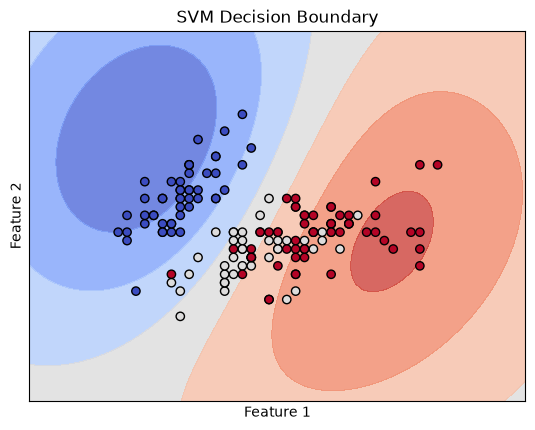

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import DecisionBoundaryDisplay

x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Adjust the input to match the expected number of features (use all four features for prediction, but only visualize the first two)
grid_points = np.c_[
    xx.ravel(), yy.ravel(),
    np.zeros((xx.ravel().shape[0], 2))
]

fig, ax = plt.subplots()
disp = DecisionBoundaryDisplay.from_estimator(
    svm_regressor,
    grid_points[:, :2],
    response_method="predict",
    plot_method="contourf",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
    ax=ax
)
ax.scatter(
    X[:, 0], X[:, 1], c=y, edgecolors='k',
    marker='o', cmap=plt.cm.coolwarm
)
ax.set_title("SVM Decision Boundary")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_xticks(())
ax.set_yticks(())
plt.show()

> **Book correction (what this figure shows).** The model plotted is the **`SVR` regressor**, not a classifier, so the colours are the regression's *predicted value* (a continuous number between about 0 and 2 that the book treats as a class id) — **not** class regions.
> The book's text says the figure shows "an SVM's ability to find non-linear boundaries between classes" and that "darker regions indicate areas where the trained SVM is **more certain** to belong to a given class, with the region in between indicating more uncertainty".
> Neither holds: dark red/blue simply mean a high/low predicted value (the extremes of the colour scale), and the blend in the middle is the regression interpolating between them. A regressor has no notion of "certainty of class".
> (Also, the "visualise the first two features only" trick of padding the other two with zeros is irrelevant here, because `from_estimator` is given only the first two columns of `grid_points`, which is what `svm_regressor` was trained on.)

A real classifier boundary, with the actual class regions, margins and support vectors for a three-class `SVC` on the same two features, is shown next (**Extension**):

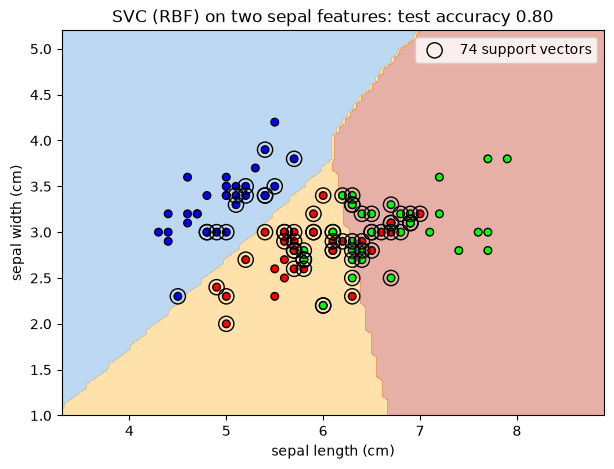

In [8]:
Xf_train = X_train[:, :2]
clf2 = SVC(kernel="rbf", C=1).fit(Xf_train, y_train)
fig, ax = plt.subplots(figsize=(7, 5))
DisplayCls = DecisionBoundaryDisplay.from_estimator(clf2, Xf_train, response_method="predict", alpha=.35, ax=ax,
                                                    xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
ax.scatter(Xf_train[:, 0], Xf_train[:, 1], c=y_train, cmap="brg", edgecolor="k", s=30)
ax.scatter(clf2.support_vectors_[:, 0], clf2.support_vectors_[:, 1], s=120, facecolors="none", edgecolors="k", label=f"{clf2.n_support_.sum()} support vectors")
ax.set_title(f"SVC (RBF) on two sepal features: test accuracy {clf2.score(X_test[:, :2], y_test):.2f}"); ax.legend(); plt.show()

Here the colours are genuine class regions (setosa is cleanly separated; versicolor and virginica overlap in the two *sepal* features, so errors are unavoidable with only these two).

**Extension — `SVC` is multiclass by one-vs-one.** SVMs are inherently binary; `SVC` handles $K$ classes by training $K(K-1)/2$ binary SVMs (one per pair of classes) and voting:

In [9]:
from sklearn.datasets import make_blobs
X4, y4 = make_blobs(n_samples=200, centers=4, cluster_std=1.2, random_state=2024)          # 4 classes make the two output shapes differ
ovo = SVC(kernel="linear", decision_function_shape="ovo").fit(X4, y4)
ovr = SVC(kernel="linear", decision_function_shape="ovr").fit(X4, y4)
K = len(ovo.classes_)
print(f"classes: {K} -> binary SVMs trained internally: K(K-1)/2 = {K * (K - 1) // 2}")
print("decision_function shape with 'ovo':", ovo.decision_function(X4[:3]).shape, "-> one column per PAIR of classes (0v1, 0v2, 0v3, 1v2, 1v3, 2v3)")
print("decision_function shape with 'ovr':", ovr.decision_function(X4[:3]).shape, "-> the pairwise votes aggregated back to one column per class (default)")
print("predictions identical either way:", (ovo.predict(X4) == ovr.predict(X4)).all(), "(decision_function_shape changes only the shape of the output)")

classes: 4 -> binary SVMs trained internally: K(K-1)/2 = 6
decision_function shape with 'ovo': (3, 6) -> one column per PAIR of classes (0v1, 0v2, 0v3, 1v2, 1v3, 2v3)
decision_function shape with 'ovr': (3, 4) -> the pairwise votes aggregated back to one column per class (default)
predictions identical either way: True (decision_function_shape changes only the shape of the output)


**Extension — `SVR` on a real continuous target** (the book's regression example used class labels). Predict diabetes disease progression, with scaling and a tuned `C` / `epsilon` (SVR ignores errors smaller than `epsilon`):

In [10]:
from sklearn.datasets import load_diabetes
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import Ridge

Xd, yd = load_diabetes(return_X_y=True)
for name, est in {"Ridge (Chapter 5)": Ridge(alpha=1.0),
                  "SVR rbf, C=1 (default)": SVR(),
                  "SVR rbf scaled, C=1": make_pipeline(StandardScaler(), SVR(C=1)),
                  "SVR rbf scaled, C=100": make_pipeline(StandardScaler(), SVR(C=100, epsilon=1.0, gamma=0.003)),
                  "SVR linear scaled, C=1": make_pipeline(StandardScaler(), SVR(kernel="linear", C=1))}.items():
    print(f"{name:26s} 5-fold CV R2 = {cross_val_score(est, Xd, yd, cv=5, scoring='r2').mean():6.3f}")

Ridge (Chapter 5)          5-fold CV R2 =  0.410
SVR rbf, C=1 (default)     5-fold CV R2 =  0.147
SVR rbf scaled, C=1        5-fold CV R2 =  0.147


SVR rbf scaled, C=100      5-fold CV R2 =  0.477


SVR linear scaled, C=1     5-fold CV R2 =  0.477


Default `SVR` is poor here (R² ≈ 0.15): the target is on a scale of tens to hundreds, while the default `C=1` and `epsilon=0.1` implicitly assume a unit-scale target, so the model is over-regularised and its predictions are shrunk towards the mean — SVM hyper-parameters are scale-dependent,
and the target may need scaling too. With a larger `C` the SVR reaches R² ≈ 0.48, above the Ridge(α=1) of Chapter 5 (0.41). (The scaled and unscaled `C=1` rows are identical because `load_diabetes` already returns standardised features, so `StandardScaler` changes nothing.
The "rbf, C=100" and "linear" rows both land at ≈ 0.48 because a very small `gamma` makes the RBF kernel behave almost linearly.)

### Theory
* **Hard margin (separable data):** minimise $\tfrac12\lVert w\rVert^2$ subject to $y_i(w^\top x_i+b)\ge1$. The margin width is $2/\lVert w\rVert$, so minimising $\lVert w\rVert$ maximises the margin.
* **Soft margin (the usual case):** introduce slack $\xi_i\ge0$ and minimise $\tfrac12\lVert w\rVert^2+C\sum_i\xi_i$ subject to $y_i(w^\top x_i+b)\ge1-\xi_i$. Equivalently, minimise the **hinge loss** $\sum_i\max(0,\,1-y_if(x_i))$ plus an L2 penalty $\tfrac1{2C}\lVert w\rVert^2$.
  Large `C` → punish violations heavily (narrow margin, low bias, high variance); small `C` → wide margin (high bias, low variance).
* **Support vectors** are the points with non-zero dual coefficient $\alpha_i$: those on or inside the margin or misclassified. The prediction $f(x)=\sum_i\alpha_iy_iK(x_i,x)+b$ uses only them.
* **Decision rule:** the sign of $f(x)$; $|f(x)|$ is proportional to the distance from the hyperplane (a *score*, not a probability).
* **Practical:** SVMs are **scale-sensitive** (standardise the features first); training cost grows between $O(n^2)$ and $O(n^3)$ in the number of samples (so `LinearSVC` / `SGDClassifier` are preferred for very large $n$); `SVC` is deterministic and convex (one global optimum).
* **`SVR`:** fits a tube of half-width $\varepsilon$ around the data; points inside the tube cost nothing, outside they cost linearly (the $\varepsilon$-insensitive loss).

### Hands-on workflow (from the book)
Load Iris → clean (nothing to do) → `SVC` → fit → predict → accuracy and classification report → try different kernels (Section 2).

## 2. Kernel functions and their applications

**Summary.** Kernel functions give SVMs their power. By *implicitly* mapping the data to a higher-dimensional space they let a **linear** boundary there correspond to a **non-linear** boundary in the original space.
The book's analogy: an accordion — compressed (flat) it is our feature space; expand it and the data spread along a new dimension where a flat cut can separate them; squeeze it back and that cut becomes curved.

### Getting ready
Same Iris data and split as before (imports repeated as in the book).

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import (
    accuracy_score, classification_report)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

### How to do it… — the polynomial kernel, then the RBF kernel
(The linear kernel was already used in Section 1.)

In [12]:
def styled(y_true, y_hat):
    rep = pd.DataFrame(classification_report(y_true, y_hat, output_dict=True)).transpose()
    return (rep.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
            .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

# polynomial kernel
svm_poly = SVC(kernel='poly', degree=3)
svm_poly.fit(X_train, y_train)
y_pred_poly = svm_poly.predict(X_test)
accuracy_poly = accuracy_score(y_test, y_pred_poly)
print(f"Polynomial Kernel Accuracy: {accuracy_poly:.2f}")
display(styled(y_test, y_pred_poly))

# RBF kernel
svm_rbf = SVC(kernel='rbf')
svm_rbf.fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"RBF Kernel Accuracy: {accuracy_rbf:.2f}")
display(styled(y_test, y_pred_rbf))

Polynomial Kernel Accuracy: 0.96


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,1.000,0.833,0.909,12
2,0.882,1.000,0.938,15
accuracy,0.956,0.956,0.956,1
macro avg,0.961,0.944,0.949,45
weighted avg,0.961,0.956,0.955,45


RBF Kernel Accuracy: 0.91


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.786,0.917,0.846,12
2,0.923,0.800,0.857,15
accuracy,0.911,0.911,0.911,1
macro avg,0.903,0.906,0.901,45
weighted avg,0.917,0.911,0.911,45


**Verification against the book:** polynomial (Figure 7.3) accuracy **0.956** (class 1: precision 1.000, recall 0.833; class 2: 0.882 / 1.000); RBF (Figure 7.4) accuracy **0.911** (class 1: 0.786 / 0.917; class 2: 0.923 / 0.800). Both reproduced ✔.
So on this split: polynomial 0.956 > linear 0.933 > RBF 0.911.

The book concludes that the polynomial kernel's "slightly better" score "tells us that the underlying data probably has a structure that is better represented … using polynomials", and that RBF "performs the worst". **Be careful:** with 45 test samples,
0.956 vs 0.933 vs 0.911 is **one sample per step** (43, 42, 41 correct). That is far too small a difference to infer anything about the data's structure. **Extension — the same comparison with cross-validation, with and without scaling:**

In [13]:
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=2024)
rows = {}
for kernel in ("linear", "poly", "rbf"):
    raw = cross_val_score(SVC(kernel=kernel), X, y, cv=cv)
    scaled = cross_val_score(make_pipeline(StandardScaler(), SVC(kernel=kernel)), X, y, cv=cv)
    rows[kernel] = {"raw: mean": raw.mean(), "raw: sd": raw.std(), "standardised: mean": scaled.mean(), "standardised: sd": scaled.std()}
pd.DataFrame(rows).T.round(3)

,raw: mean,raw: sd,standardised: mean,standardised: sd
linear,0.979,0.026,0.965,0.034
poly,0.967,0.032,0.924,0.041
rbf,0.965,0.033,0.960,0.030


Over 50 resamplings, on the raw features: linear **0.979**, polynomial 0.967, RBF 0.965 — the gaps (≈ 1 point) are smaller than the fold-to-fold standard deviation (≈ 0.03), and the **single-split ranking (polynomial > linear > RBF) does not hold**: the *linear* kernel is nominally the best.
On Iris, which is nearly linearly separable, the kernel hardly matters.

A second, less expected result: **standardising does not help here — it slightly hurts** (linear 0.979 → 0.965, polynomial 0.967 → 0.924). All four Iris features are in centimetres with similar ranges, and their *relative sizes carry information* (petal measurements discriminate the species and have larger
spread than the sepal ones); standardising equalises them and discards part of that. "Always scale before an SVM" is a good default, **not a law** — see also the wide-data example in Section 4, where scaling hurts far more.

### How it works…
**The kernel trick:** SVMs only ever need *dot products* between points. A kernel $K(x,z)=\langle\phi(x),\phi(z)\rangle$ computes the dot product in the high-dimensional feature space $\phi$ **without ever constructing $\phi(x)$**.
* **Linear:** $K(x,z)=x^\top z$.
* **Polynomial:** $K(x,z)=(\gamma\,x^\top z+r)^d$ — all feature interactions up to degree $d$. * **RBF (Gaussian):** $K(x,z)=\exp(-\gamma\lVert x-z\rVert^2)$ — similarity decays with distance.

> **Book correction (kernel descriptions).** The book says the **linear kernel** "maps the data linearly into a higher-dimensional space". It does not map anywhere: $\phi(x)=x$ — the linear kernel *is* the original feature space (that is why it can only draw straight boundaries).
> The **RBF kernel** corresponds to a mapping into an *infinite-dimensional* space (which is exactly why computing it implicitly via the kernel is essential), and its "Gaussian function" is of the *distance* between two points, not "a normal distribution" of the data.

**Extension — the kernel trick verified.** For a degree-2 polynomial kernel in 2-D with $\gamma=1, r=1$, the explicit feature map is $\phi(x)=(1,\sqrt2x_1,\sqrt2x_2,x_1^2,x_2^2,\sqrt2x_1x_2)$. The kernel value equals the dot product of the mapped points,
and an SVM using the kernel on the raw data matches a *linear* SVM on the explicitly mapped data:

In [14]:
from sklearn.metrics.pairwise import polynomial_kernel, rbf_kernel

def phi(A):                                           # explicit degree-2 feature map for 2-D input (gamma=1, coef0=1)
    a, b = A[:, 0], A[:, 1]
    return np.c_[np.ones(len(A)), np.sqrt(2) * a, np.sqrt(2) * b, a ** 2, b ** 2, np.sqrt(2) * a * b]

P = X[:6, 2:4]
print("K(x,z) = (x.z + 1)^2 :", polynomial_kernel(P[:3], P[3:], degree=2, gamma=1, coef0=1).round(3)[0])
print("phi(x).phi(z)        :", (phi(P[:3]) @ phi(P[3:]).T).round(3)[0], "<- identical, but phi has 6 dimensions vs 2")

Xk, yk = X[y != 0][:, 2:4], (y[y != 0] == 2).astype(int)
kern = SVC(kernel="poly", degree=2, gamma=1, coef0=1, C=10).fit(Xk, yk)                    # kernel on raw 2-D data
expl = SVC(kernel="linear", C=10).fit(phi(Xk), yk)                                         # linear SVM on the explicit 6-D features
print("same predictions:", (kern.predict(Xk) == expl.predict(phi(Xk))).all(), "| same number of support vectors:", kern.n_support_.sum(), expl.n_support_.sum())

g = 0.5; a, b = X[0, :2], X[1, :2]
print("\nRBF by hand exp(-gamma*||x-z||^2) =", round(np.exp(-g * np.sum((a - b) ** 2)), 6), "| sklearn rbf_kernel =", round(rbf_kernel([a], [b], gamma=g)[0, 0], 6))

K(x,z) = (x.z + 1)^2 : [ 9.86   9.    11.972]
phi(x).phi(z)        : [ 9.86   9.    11.972] <- identical, but phi has 6 dimensions vs 2
same predictions: True | same number of support vectors: 12 12

RBF by hand exp(-gamma*||x-z||^2) = 0.865022 | sklearn rbf_kernel = 0.865022


**Extension — why a higher dimension helps: the accordion in code.** Two concentric rings cannot be separated by a line. Add one new feature $z=x_1^2+x_2^2$ (the squared distance from the centre) and a *flat* cut in 3-D separates them — which projects back to a circle:

linear SVM on (x1, x2)       : accuracy 0.528 (about chance)
linear SVM on (x1, x2, x1^2+x2^2): accuracy 1.0 (flat cut in the lifted space)
RBF SVM on (x1, x2)          : accuracy 1.0 (the kernel does the lifting implicitly)


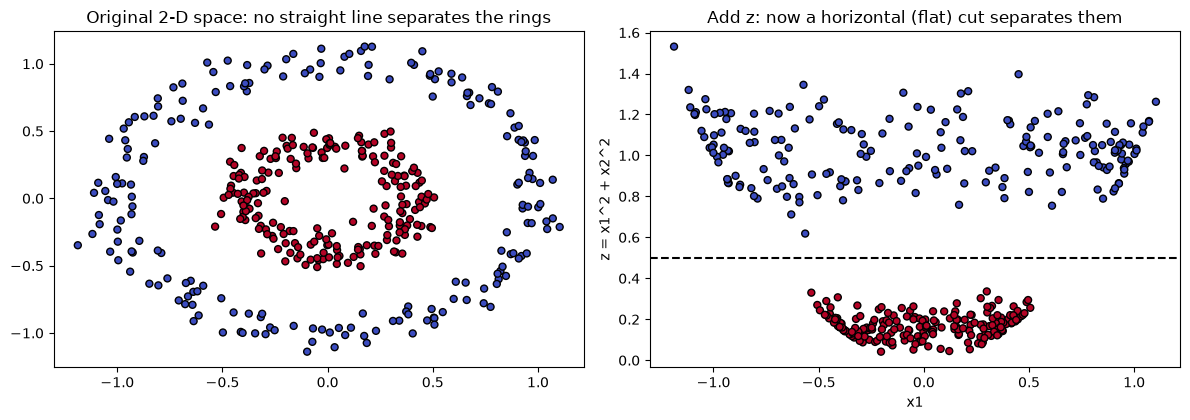

In [15]:
from sklearn.datasets import make_circles

Xc, yc = make_circles(n_samples=400, noise=0.08, factor=0.4, random_state=2024)
z = (Xc ** 2).sum(axis=1)
Xlift = np.c_[Xc, z]

print("linear SVM on (x1, x2)       : accuracy", round(cross_val_score(SVC(kernel="linear"), Xc, yc, cv=5).mean(), 3), "(about chance)")
print("linear SVM on (x1, x2, x1^2+x2^2): accuracy", round(cross_val_score(SVC(kernel="linear"), Xlift, yc, cv=5).mean(), 3), "(flat cut in the lifted space)")
print("RBF SVM on (x1, x2)          : accuracy", round(cross_val_score(SVC(kernel="rbf"), Xc, yc, cv=5).mean(), 3), "(the kernel does the lifting implicitly)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap="coolwarm", edgecolor="k", s=25); ax[0].set_title("Original 2-D space: no straight line separates the rings")
ax[1].scatter(Xc[:, 0], z, c=yc, cmap="coolwarm", edgecolor="k", s=25); ax[1].axhline(0.5, c="k", ls="--"); ax[1].set_xlabel("x1"); ax[1].set_ylabel("z = x1^2 + x2^2")
ax[1].set_title("Add z: now a horizontal (flat) cut separates them")
plt.tight_layout(); plt.show()

### Visualizing kernel effects (book)
The book trains three SVMs on the first two features only and draws their predicted regions on a fine mesh grid (step 0.01, so about 300 000 grid points).

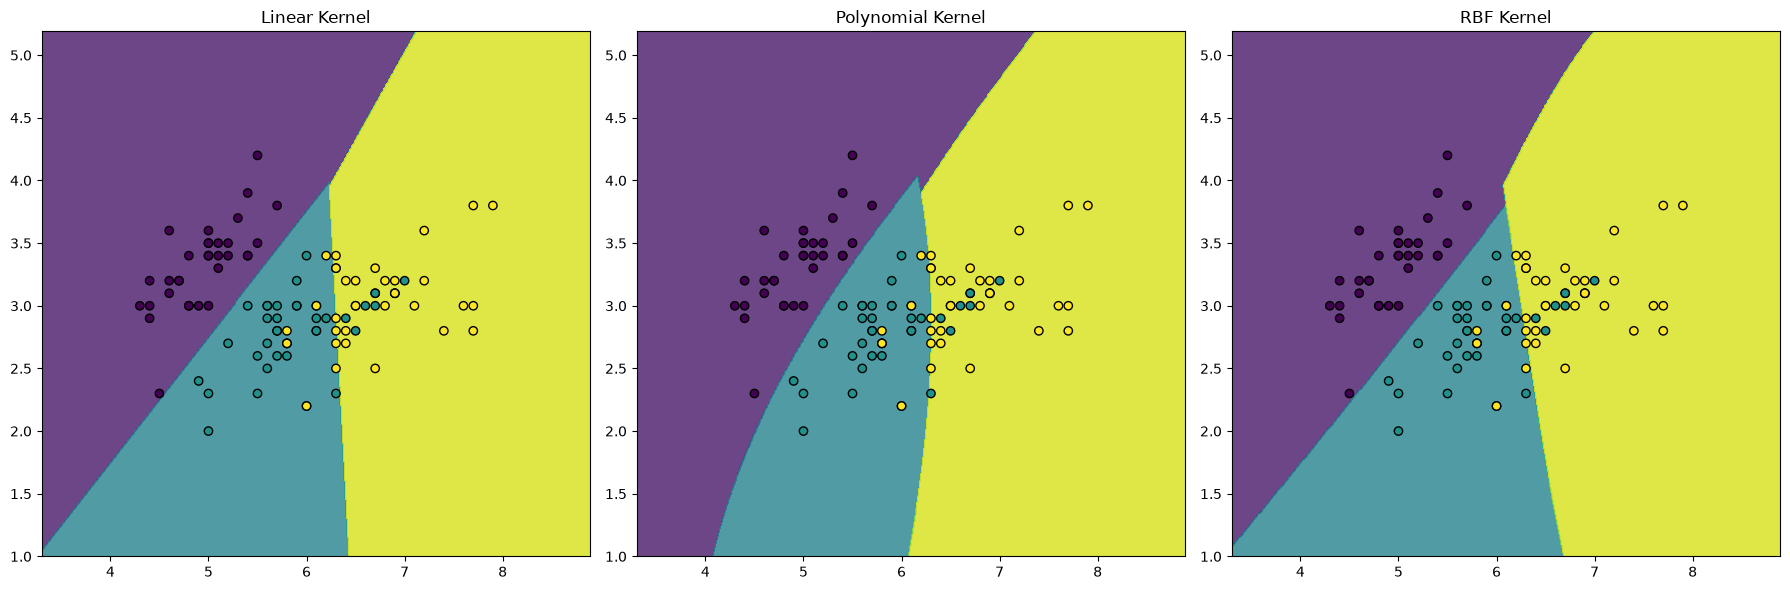

In [16]:
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

X_train_2d = X_train[:, :2]

svm_linear_2d = SVC(kernel='linear').fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel='poly').fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf').fit(X_train_2d, y_train)

Z_linear = svm_linear_2d.predict(
    np.c_[xx.ravel(), yy.ravel()])
Z_poly = svm_poly_2d.predict(
    np.c_[xx.ravel(), yy.ravel()])
Z_rbf = svm_rbf_2d.predict(
    np.c_[xx.ravel(), yy.ravel()])
Z_linear = Z_linear.reshape(xx.shape)
Z_poly = Z_poly.reshape(xx.shape)
Z_rbf = Z_rbf.reshape(xx.shape)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].contourf(xx, yy, Z_linear, alpha=0.8)
axes[0].scatter(
    X_train_2d[:, 0], X_train_2d[:, 1],
    c=y_train, edgecolors='k', marker='o'
)
axes[0].set_title("Linear Kernel")
axes[1].contourf(xx, yy, Z_poly, alpha=0.8)
axes[1].scatter(
    X_train_2d[:, 0], X_train_2d[:, 1],
    c=y_train, edgecolors='k', marker='o'
)
axes[1].set_title("Polynomial Kernel")
axes[2].contourf(xx, yy, Z_rbf, alpha=0.8)
axes[2].scatter(
    X_train_2d[:, 0], X_train_2d[:, 1],
    c=y_train, edgecolors='k', marker='o'
)
axes[2].set_title("RBF Kernel")
plt.tight_layout()
plt.show()

As the book says, the three boundaries are "not very different at first glance": the linear kernel draws straight lines, the polynomial and RBF kernels slightly curved ones. (The step "Predict class *probabilities* across the grid for each kernel" in the book's heading is a slip:
the code uses `predict`, i.e. class labels; `SVC` has no probabilities unless `probability=True`.)

**Extension — a dataset that really needs a kernel, and the effect of `gamma`.** Iris barely distinguishes the kernels; the *two moons* data does. Below: linear vs polynomial vs RBF, and the RBF kernel's `gamma` from underfitting to overfitting.

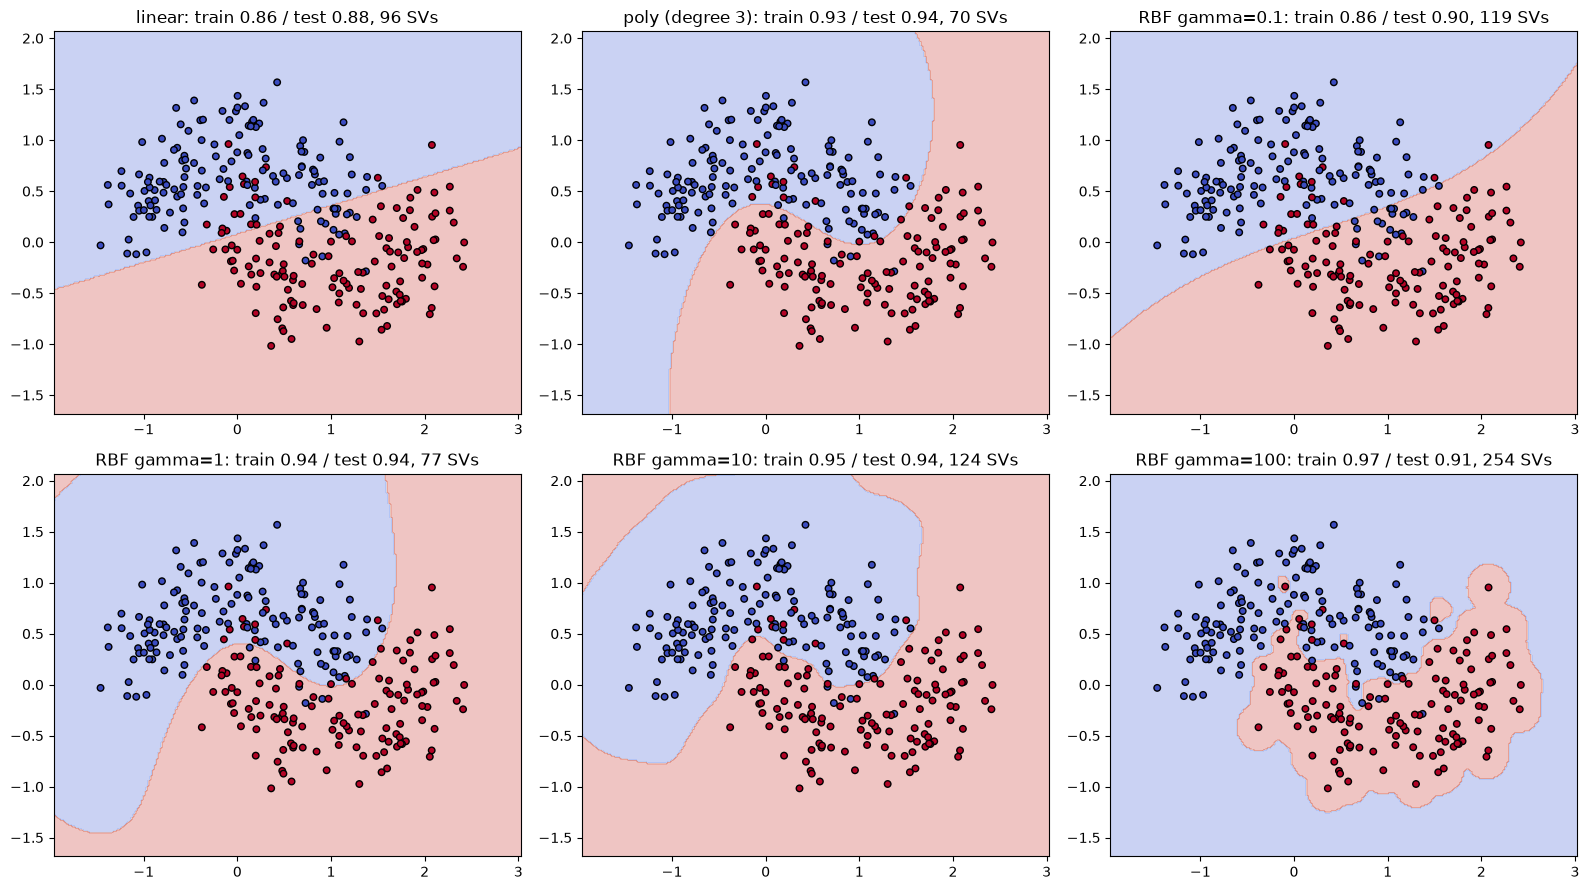

,train acc,test acc,support vectors
model,,,
linear,0.864,0.875,96
poly (degree 3),0.932,0.942,70
RBF gamma=0.1,0.864,0.900,119
RBF gamma=1,0.936,0.942,77
RBF gamma=10,0.946,0.942,124
RBF gamma=100,0.971,0.908,254


In [17]:
from sklearn.datasets import make_moons

Xm, ym = make_moons(n_samples=400, noise=0.30, random_state=2024)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.3, random_state=2024)
gx, gy = np.meshgrid(np.linspace(Xm[:, 0].min() - .5, Xm[:, 0].max() + .5, 250), np.linspace(Xm[:, 1].min() - .5, Xm[:, 1].max() + .5, 250))

variants = {"linear": SVC(kernel="linear"), "poly (degree 3)": SVC(kernel="poly", degree=3, coef0=1),
            "RBF gamma=0.1": SVC(kernel="rbf", gamma=0.1), "RBF gamma=1": SVC(kernel="rbf", gamma=1),
            "RBF gamma=10": SVC(kernel="rbf", gamma=10), "RBF gamma=100": SVC(kernel="rbf", gamma=100)}
fig, axes = plt.subplots(2, 3, figsize=(16, 9)); rows = []
for ax, (name, m) in zip(axes.ravel(), variants.items()):
    m.fit(Xm_tr, ym_tr)
    ax.contourf(gx, gy, m.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), alpha=.3, cmap="coolwarm")
    ax.scatter(Xm_tr[:, 0], Xm_tr[:, 1], c=ym_tr, cmap="coolwarm", edgecolor="k", s=22)
    tr, te = m.score(Xm_tr, ym_tr), m.score(Xm_te, ym_te); ax.set_title(f"{name}: train {tr:.2f} / test {te:.2f}, {m.n_support_.sum()} SVs")
    rows.append({"model": name, "train acc": tr, "test acc": te, "support vectors": int(m.n_support_.sum())})
plt.tight_layout(); plt.show()
pd.DataFrame(rows).set_index("model").round(3)

The linear kernel cuts the moons with a straight line (train 0.864 / test 0.875); polynomial and RBF follow the curve (≈ 0.94 test). **`gamma` controls the reach of each point**: small `gamma` (0.1) → each point influences a wide area → a smooth, nearly linear boundary that underfits (train 0.864);
`gamma=1` → well matched (0.936 / 0.942); large `gamma` → each point influences only its immediate neighbourhood → islands around single points. The overfitting shows up clearly only at the extreme `gamma=100`: **train 0.971 but test 0.908**, and 254 of the 280 training points become
support vectors (the model has essentially memorised the data). At `gamma=10` the boundary is already jagged but test accuracy is still 0.942 — a jagged boundary is a *warning sign*, not by itself proof of poor generalisation; the train–test gap and cross-validation are the evidence.

### There's more… (book): other kernels
The book suggests the **sigmoid** kernel and **custom kernels**. In scikit-learn a custom kernel is any function returning the Gram matrix, or a precomputed Gram matrix (`kernel='precomputed'`):

In [18]:
def my_linear_kernel(A, B):
    return A @ B.T                                        # a hand-written kernel: the dot product

custom = SVC(kernel=my_linear_kernel).fit(X_train, y_train)
builtin = SVC(kernel="linear").fit(X_train, y_train)
print("custom callable kernel == built-in linear:", (custom.predict(X_test) == builtin.predict(X_test)).all(), "| accuracy", round(custom.score(X_test, y_test), 4))

gram_tr = X_train @ X_train.T; gram_te = X_test @ X_train.T          # precomputed Gram matrices
pre = SVC(kernel="precomputed").fit(gram_tr, y_train)
print("precomputed Gram matrix  == built-in linear:", (pre.predict(gram_te) == builtin.predict(X_test)).all())

sig = SVC(kernel="sigmoid").fit(StandardScaler().fit(X_train).transform(X_train), y_train)
print("sigmoid kernel (scaled data) accuracy:", round(sig.score(StandardScaler().fit(X_train).transform(X_test), y_test), 4), "(tanh(gamma*x.z + r); rarely the best choice)")

custom callable kernel == built-in linear: True | accuracy 0.9333
precomputed Gram matrix  == built-in linear: True
sigmoid kernel (scaled data) accuracy: 0.9111 (tanh(gamma*x.z + r); rarely the best choice)


### Theory
* **Mercer's condition:** a function $K$ is a valid kernel if its Gram matrix is symmetric positive semi-definite; then $K(x,z)=\langle\phi(x),\phi(z)\rangle$ for some feature map $\phi$ (possibly infinite-dimensional).
* **Kernel parameters:** `degree` ($d$), `gamma` ($\gamma$) and `coef0` ($r$) for the polynomial kernel; `gamma` for RBF and sigmoid. The default `gamma='scale'` is $1/(n_{features}\cdot\mathrm{Var}(X))$, which makes the default depend on the data scale.
* **Which kernel?** Start with linear (fast, strong when many features); try RBF as the default non-linear choice (one parameter, flexible); use polynomial when interactions of a known degree are expected; use custom kernels for structured data (strings, graphs).
* **Always scale** before RBF/polynomial kernels: distances and dot products are dominated by large-range features.
* **Cost:** kernel SVMs store the support vectors and compute $K(x,\cdot)$ at prediction time; an overfit RBF model has many support vectors and is slow.

### Hands-on workflow (from the book)
Load Iris → `SVC` with linear, polynomial and RBF kernels → evaluate → visualise the decision boundaries → experiment with the kernel parameters (`degree` for polynomial, `gamma` for RBF) — done above on Iris and on the moons data, where the effect is visible.

## 3. Tuning SVM parameters

**Summary.** As for every model, hyper-parameter tuning improves SVMs. The recipe uses a classic **grid search with cross-validation** over `C`, `kernel` and `degree`.

### Getting ready

In [19]:
from sklearn.model_selection import (
    train_test_split, GridSearchCV)
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import (
    accuracy_score, classification_report)
import pandas as pd

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

### How to do it…

In [20]:
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation Score: {best_score:.2f}")

best_model = SVC(**best_params)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(
    y_test, y_pred, output_dict=True)
).transpose()
styled_report_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.99
Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


**Verification against the book:** Figure 7.6 shows `Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}`, `Best Cross-Validation Score: 0.99`, `Accuracy: 0.93` (and the same report as the default linear SVM) — reproduced exactly ✔.
The book comments that "the results are almost the same as … our default parameters. This is not a failure of hyperparameter optimization, but a reflection of the simplicity of our dataset".

**Extension — is "the best" unique, and how wasteful is this grid?**

In [21]:
res = pd.DataFrame(grid_search.cv_results_)
res["kernel"] = res["param_kernel"]; res["C"] = res["param_C"]; res["degree"] = res["param_degree"]
print("grid size:", len(res), "combinations x 5 folds =", len(res) * 5, "fits")
print("configurations tied for first place:", int((res["rank_test_score"] == 1).sum()))
display(res.sort_values("rank_test_score")[["kernel", "C", "degree", "mean_test_score", "std_test_score", "rank_test_score"]].head(10).round(4))

# 'degree' only matters for the polynomial kernel: the linear / rbf rows are duplicates for each degree
dup = res[res.kernel != "poly"].groupby(["kernel", "C"])["mean_test_score"].nunique()
print("\nlinear/rbf: distinct scores per (kernel, C) over the 3 degrees ->", dup.unique().tolist(), "(1 = the three degrees give identical results)")
print("effective distinct models:", 3 + 3 + 9, "of", len(res))

grid size: 27 combinations x 5 folds = 135 fits
configurations tied for first place: 8


,kernel,C,degree,mean_test_score,std_test_score,rank_test_score
12,linear,1.0,3,0.9905,0.0190,1
11,poly,1.0,2,0.9905,0.0190,1
9,linear,1.0,2,0.9905,0.0190,1
15,linear,1.0,4,0.9905,0.0190,1
8,poly,0.1,4,0.9905,0.0190,1
25,rbf,10.0,4,0.9905,0.0190,1
22,rbf,10.0,3,0.9905,0.0190,1
19,rbf,10.0,2,0.9905,0.0190,1
20,poly,10.0,2,0.9810,0.0233,9
5,poly,0.1,3,0.9810,0.0233,9



linear/rbf: distinct scores per (kernel, C) over the 3 degrees -> [1] (1 = the three degrees give identical results)
effective distinct models: 15 of 27


> **Book correction / remark (grid design and ties).** (1) `degree` only affects the polynomial kernel, so for `linear` and `rbf` the three `degree` values are **identical, wasted fits**: only 15 of the 27 combinations are distinct. The right way is a *list of grids*:
> `[{'kernel': ['linear'], 'C': ...}, {'kernel': ['rbf'], 'C': ..., 'gamma': ...}, {'kernel': ['poly'], 'C': ..., 'degree': ...}]`. (2) The "best" configuration is **not unique** — here **8** configurations tie for the top CV score (0.9905); scikit-learn simply reports the first one,
> so `poly`, degree 4, `C=0.1` has no special merit over e.g. an RBF with `C=1`. The CV standard deviation (≈ 0.02) and the test set of 45 points mean these differences are noise.
> (3) The grid never tunes `gamma`, the most important RBF parameter (the book's exercise step 8 even suggests experimenting with it).

**Extension — the grid the book should have used:** a list of grids, scaling inside a pipeline, tuning `gamma`.

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe = Pipeline([("scale", StandardScaler()), ("svc", SVC())])
grids = [
    {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10, 100]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.001, 0.01, 0.1, 1]},
    {"svc__kernel": ["poly"], "svc__C": [0.1, 1, 10], "svc__degree": [2, 3, 4]},
]
gs2 = GridSearchCV(pipe, grids, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)).fit(X_train, y_train)
r2 = pd.DataFrame(gs2.cv_results_)
print("combinations:", len(r2), "(vs 27 in the book's grid)")
print("best:", gs2.best_params_, "| CV accuracy", round(gs2.best_score_, 4), "| test accuracy", round(gs2.score(X_test, y_test), 4))
print("configurations within 1 standard error of the best:", int((r2["mean_test_score"] >= gs2.best_score_ - r2.loc[gs2.best_index_, "std_test_score"] / np.sqrt(15)).sum()))

combinations: 30 (vs 27 in the book's grid)
best: {'svc__C': 1, 'svc__kernel': 'linear'} | CV accuracy 0.9841 | test accuracy 0.9333
configurations within 1 standard error of the best: 5


### How it works…
Grid search evaluates every parameter combination with cross-validation; it is exhaustive, so more hyper-parameters means longer runs. The parameters:
* **`C`** (regularisation): the trade-off between a wide margin and training errors; a high `C` makes the model less tolerant of misclassifications (book ✔).
* **Kernel parameters:** `degree` (polynomial) and `gamma` (RBF) control the shape of the mapping.

### Visualizing hyperparameter effects (book)
Cross-validation score against `C` for an RBF SVM (`C` from $10^{-4}$ to $10^{4}$, 10 values).

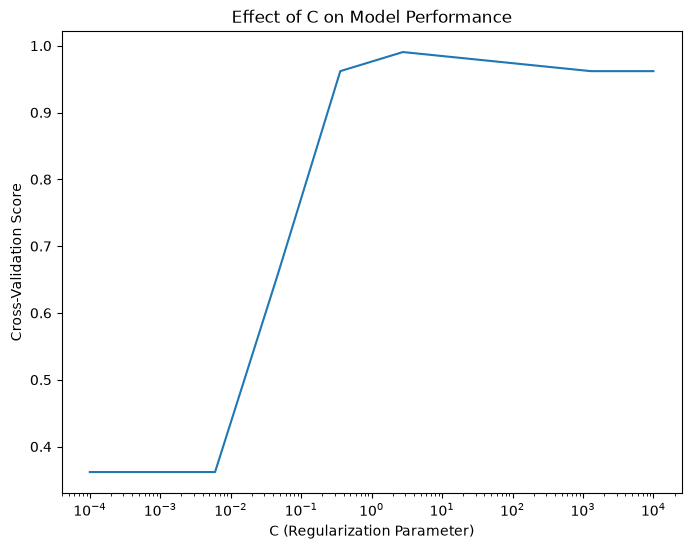

         C  mean CV score
    0.0001          0.362
    0.0008          0.362
    0.0060          0.362
    0.0464          0.657
    0.3594          0.962
    2.7826          0.990
   21.5443          0.981
  166.8101          0.971
 1291.5497          0.962
10000.0000          0.962


In [23]:
param_grid_c = {
    'C': np.logspace(-4, 4, 10),
    'kernel': ['rbf']
}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

plt.figure(figsize=(8, 6))
plt.plot(
    grid_search_c.param_grid['C'],
    grid_search_c.cv_results_['mean_test_score']
)
plt.xscale('log')
plt.xlabel('C (Regularization Parameter)')
plt.ylabel('Cross-Validation Score')
plt.title('Effect of C on Model Performance')
plt.show()
print(pd.DataFrame({"C": np.logspace(-4, 4, 10).round(4), "mean CV score": grid_search_c.cv_results_['mean_test_score'].round(3)}).to_string(index=False))

The book says "we can see diminishing returns … model performance plateaus around $C=10^1$". Reading the numbers: the score is flat at 0.36 (the majority-class rate) for tiny `C` (everything is heavily regularised towards a constant prediction), **rises steeply between $C\approx0.03$ and $C\approx1$,
peaks at $C\approx2.8$ (0.990), and then declines slightly** (0.981 at $C\approx22$, 0.971 at $C\approx170$, 0.962 beyond) as the model starts to fit noise. So it is a *peak* near $C\approx3$ rather than a plateau that begins at 10 — a small effect on Iris, but the shape (underfit → good → mild overfit) is the standard one. The vertical axis hides how small the right-hand decline is (a few test points).

**Extension — tune both `C` and `gamma` and look at the whole surface** (breast cancer data, scaled; the heat-map shows where the model underfits, fits well, or overfits):

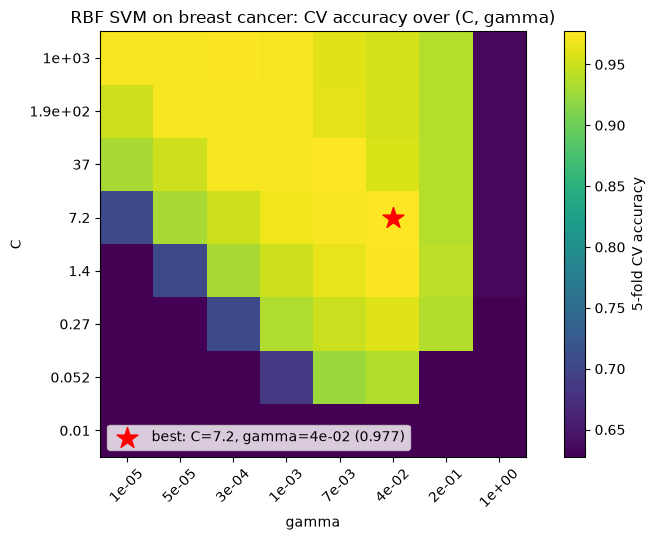

worst corner (large gamma, any C): 0.627 | tiny C and tiny gamma: 0.627


In [24]:
from sklearn.datasets import load_breast_cancer
Xb, yb = load_breast_cancer(return_X_y=True)
Cs, gammas = np.logspace(-2, 3, 8), np.logspace(-5, 0, 8)
grid_cg = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf")), {"svc__C": Cs, "svc__gamma": gammas}, cv=5).fit(Xb, yb)
heat = grid_cg.cv_results_["mean_test_score"].reshape(len(Cs), len(gammas))

fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(heat, cmap="viridis", origin="lower"); plt.colorbar(im, label="5-fold CV accuracy")
ax.set_xticks(range(len(gammas))); ax.set_xticklabels([f"{g:.0e}" for g in gammas], rotation=45); ax.set_yticks(range(len(Cs))); ax.set_yticklabels([f"{c:.2g}" for c in Cs])
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("RBF SVM on breast cancer: CV accuracy over (C, gamma)")
i, j = np.unravel_index(heat.argmax(), heat.shape); ax.scatter(j, i, marker="*", s=250, c="red", label=f"best: C={Cs[i]:.2g}, gamma={gammas[j]:.0e} ({heat.max():.3f})"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()
print("worst corner (large gamma, any C):", round(heat[:, -1].min(), 3), "| tiny C and tiny gamma:", round(heat[0, 0], 3))

A **diagonal ridge** of good models runs from (small `gamma`, large `C`) to (large `gamma`, small `C`): the two parameters trade off. The bottom-left (both tiny: too much regularisation and too smooth) and the right-hand columns (large `gamma`: each point is an island, overfit) are poor.
Tuning only `C` (as the book did) misses half the picture.

**Extension — randomized search** (the book names it in "There's more"): sample `C` and `gamma` from log-uniform distributions instead of a fixed grid.

In [25]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

rs = RandomizedSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf")), {"svc__C": loguniform(1e-2, 1e3), "svc__gamma": loguniform(1e-5, 1)},
                        n_iter=25, cv=5, random_state=2024).fit(Xb, yb)
print("RandomizedSearchCV (25 samples) best:", {k: float(f"{v:.3g}") for k, v in rs.best_params_.items()}, "| CV accuracy", round(rs.best_score_, 4), "| vs grid (64 combos):", round(grid_cg.best_score_, 4))

RandomizedSearchCV (25 samples) best: {'svc__C': 21.0, 'svc__gamma': 0.0108} | CV accuracy 0.9789 | vs grid (64 combos): 0.9772


### Theory
* **`C` and `gamma` jointly control complexity:** large `C` + large `gamma` = most flexible (overfits); small `C` + small `gamma` = most rigid (underfits). Search them on a **logarithmic** scale.
* **Selection bias:** the best CV score is optimistically biased (selected as the maximum of many); report the test score once, and prefer a simpler configuration among near-ties (the "one standard error rule").
* **Search design:** use a list of grids so parameters only appear where they matter; put the scaler inside the `Pipeline`; random search covers continuous ranges efficiently.

### Hands-on workflow (from the book)
Load Iris → `SVC` → parameter grid → `GridSearchCV` → train with the best parameters → evaluate → plot how hyper-parameters affect performance (done above, plus the `C`–`gamma` surface).

## 4. SVMs in high-dimensional spaces

**Summary.** SVMs handle data with many features relative to the number of samples (a **wide** dataset — e.g. a rare event measured by instruments that each record hundreds of values). The recipe builds a synthetic wide dataset: 1 000 samples × 1 000 features, only 50 informative.

### Getting ready

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import make_classification
from sklearn.metrics import (
    accuracy_score, classification_report)
import pandas as pd
import numpy as np

X, y = make_classification(
    n_samples=1000, n_features=1000,
    n_informative=50, n_redundant=0, random_state=2024
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)
print(X_train.shape, X_test.shape, "| classes:", np.bincount(y))

(700, 1000) (300, 1000) | classes: [503 497]


### How to do it…

In [27]:
svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(
    y_test, y_pred, output_dict=True)
).transpose()
styled_report_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.765,0.765,0.765,162
1,0.725,0.725,0.725,138
accuracy,0.747,0.747,0.747,1
macro avg,0.745,0.745,0.745,300
weighted avg,0.747,0.747,0.747,300


**Verification against the book:** Figure 7.8 reports accuracy **0.747** (class 0: 0.765 / 0.765; class 1: 0.725 / 0.725; support 162 / 138) — reproduced ✔ (0.7467). The book comments that the defaults "did not elicit the strongest performance! Good that we know how to address these types of performance issues now" —
but **the recipe never actually addresses it**. The Extension below does.

### Visualizing high-dimensional data (book): PCA to 2-D

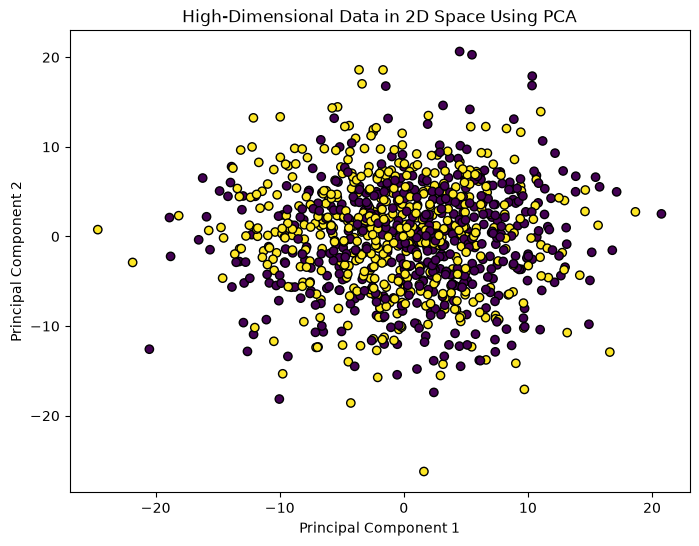

variance explained by the 2 plotted components: [0.0245 0.0212] = only 4.6% of the total


In [28]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0], X_pca[:, 1], c=y,
    edgecolors='k', marker='o'
)
plt.title("High-Dimensional Data in 2D Space Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()
print("variance explained by the 2 plotted components:", pca.explained_variance_ratio_.round(4), "= only", f"{pca.explained_variance_ratio_.sum():.1%}", "of the total")

The classes overlap heavily in this 2-D picture ("the data is quite messy"). **But this plot says little about how separable the data is in all 1 000 dimensions:** the two components show only **≈ 5 % of the variance** (4.6 %),
and PCA is *unsupervised* — it picks directions of large variance, not directions that separate the classes, while the information is spread over 50 informative features. A 2-D projection can look hopeless for data that a classifier in the full space separates well — the next cell
shows that PCA itself, with **50 components instead of 2**, gives the best accuracy of all.

**Extension — how to address the poor performance.** First a diagnostic that will explain a surprise below: how large are the informative features compared with the noise features? (`make_classification` hides which columns are informative, so I use the 50 columns most related to the class, by an ANOVA F-test, as a proxy.)

In [29]:
from sklearn.feature_selection import SelectKBest, f_classif

f_scores, _ = f_classif(X_train, y_train)
top50 = np.argsort(-f_scores)[:50]
sd = X_train.std(axis=0)
print(f"std of the 50 most class-related features : mean {sd[top50].mean():.2f}")
print(f"std of the other 950 (mostly noise) features: mean {np.delete(sd, top50).mean():.2f}")
pca50 = PCA(n_components=50, random_state=0).fit(X_train)
print(f"variance explained by 50 PCA components    : {pca50.explained_variance_ratio_.sum():.1%}  (vs {PCA(2).fit(X_train).explained_variance_ratio_.sum():.1%} for 2 components)")

std of the 50 most class-related features : mean 2.57
std of the other 950 (mostly noise) features: mean 1.08
variance explained by 50 PCA components    : 51.7%  (vs 4.8% for 2 components)


In this synthetic dataset the **informative features have a much larger spread (std ≈ 2.6) than the noise features (std ≈ 1.1)**: *the scale itself carries signal*. Remember this when reading the next table — it means that **standardising the features is harmful here**, because it puts the 950 noise
columns on the same footing as the 50 informative ones. Compare ways of improving the SVM on the same split:

In [30]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
import time

candidates = {
    "book: SVC(linear), C=1": SVC(kernel="linear"),
    "SVC(linear), C=0.001 (stronger regularisation)": SVC(kernel="linear", C=0.001),
    "StandardScaler -> SVC(linear), C=0.001": make_pipeline(StandardScaler(), SVC(kernel="linear", C=0.001)),
    "SVC(rbf) default (unscaled)": SVC(kernel="rbf"),
    "StandardScaler -> SVC(rbf)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "SelectKBest(50) -> SVC(rbf), unscaled": make_pipeline(SelectKBest(f_classif, k=50), SVC(kernel="rbf")),
    "StandardScaler -> SelectKBest(50) -> SVC(rbf)": make_pipeline(StandardScaler(), SelectKBest(f_classif, k=50), SVC(kernel="rbf")),
    "PCA(50) -> SVC(rbf), unscaled": make_pipeline(PCA(n_components=50, random_state=0), SVC(kernel="rbf")),
    "StandardScaler -> PCA(50) -> SVC(rbf)": make_pipeline(StandardScaler(), PCA(n_components=50, random_state=0), SVC(kernel="rbf")),
}
rows = []
for name, est in candidates.items():
    t0 = time.time(); est.fit(X_train, y_train); fit_t = time.time() - t0
    rows.append({"model": name, "test accuracy": est.score(X_test, y_test), "train accuracy": est.score(X_train, y_train), "fit time (s)": fit_t})
pd.DataFrame(rows).set_index("model").round(3)

,test accuracy,train accuracy,fit time (s)
model,,,
"book: SVC(linear), C=1",0.747,1.000,0.081
"SVC(linear), C=0.001 (stronger regularisation)",0.773,0.954,0.077
"StandardScaler -> SVC(linear), C=0.001",0.640,0.954,0.120
SVC(rbf) default (unscaled),0.883,0.999,0.093
StandardScaler -> SVC(rbf),0.647,1.000,0.110
"SelectKBest(50) -> SVC(rbf), unscaled",0.900,0.979,0.039
StandardScaler -> SelectKBest(50) -> SVC(rbf),0.793,0.979,0.048
"PCA(50) -> SVC(rbf), unscaled",0.953,0.997,0.179
StandardScaler -> PCA(50) -> SVC(rbf),0.553,0.923,0.104


Reading the table (test accuracy on the 300 held-out points):
* **Overfitting is visible in the train/test gap:** the book's default linear SVM has train accuracy **1.000** and test 0.747 — with 700 points and 1 000 features it fits the training set perfectly. Stronger regularisation (`C=0.001`) narrows the gap and lifts test accuracy to 0.773.
* **The RBF kernel helps a lot** — 0.883 with the default settings: the class structure here is not purely linear.
* **Standardising makes everything much worse** (linear 0.773 → 0.640; RBF 0.883 → 0.647), for the reason found above: it erases the scale signal and amplifies 950 noise columns. This is the opposite of the usual advice, and a reminder to *check* rather than assume.
* **Reducing the dimensionality works — if you do not standardise first.** `PCA(50)` on the raw features followed by an RBF SVM is the **best model: 0.953**; `SelectKBest(50)` on the raw features is 0.900. Put the same steps *after* a `StandardScaler` and they collapse (PCA: 0.55; SelectKBest: 0.79), because PCA then
  chooses directions of maximal variance among *equal-variance* standardised features, which are mostly noise. Without scaling, the high-variance directions are the informative ones. Selectors and PCA must sit **inside** the pipeline so they are fitted on training data only.

In [31]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=2024)
rows = {}
for name in ("book: SVC(linear), C=1", "SVC(linear), C=0.001 (stronger regularisation)", "SVC(rbf) default (unscaled)", "StandardScaler -> SVC(rbf)",
             "SelectKBest(50) -> SVC(rbf), unscaled", "PCA(50) -> SVC(rbf), unscaled"):
    s = cross_val_score(candidates[name], X, y, cv=cv); rows[name] = {"CV mean": s.mean(), "CV sd": s.std()}
pd.DataFrame(rows).T.round(3)

,CV mean,CV sd
"book: SVC(linear), C=1",0.717,0.024
"SVC(linear), C=0.001 (stronger regularisation)",0.750,0.027
SVC(rbf) default (unscaled),0.872,0.025
StandardScaler -> SVC(rbf),0.634,0.031
"SelectKBest(50) -> SVC(rbf), unscaled",0.898,0.026
"PCA(50) -> SVC(rbf), unscaled",0.954,0.009


The ranking holds under cross-validation on all 1 000 samples: **PCA(50) → RBF ≈ 0.95 > SelectKBest(50) → RBF ≈ 0.90 > default RBF ≈ 0.87 > regularised linear ≈ 0.75 > the book's default linear ≈ 0.72 > standardised RBF ≈ 0.63.**
So the book's remark "SVMs are particularly effective in high-dimensional spaces" holds *in relative terms*, but defaults (and a reflexive `StandardScaler`) can still cost 20–30 points; what fixed the problem was regularisation, a non-linear kernel and dimensionality reduction —
techniques from Chapters 2–3 that the book promises ("good that we know how to address these") but never applies in this recipe.

### How it works…
SVMs deal with high-dimensional data efficiently because of kernels and because the cost of a kernel SVM depends on the number of **samples** (the kernel matrix is $n\times n$), not on the number of features $p$. The book's guidance:
* **Linear kernel:** suitable when the data is (close to) linearly separable or when the number of features is large (in high dimensions, data become *more* easily linearly separable: with $p\ge n$ points in general position are always separable by a hyperplane).
* **Non-linear kernels (RBF, polynomial):** for complex boundaries, at the price of tuning (`gamma`, `C`) and of overfitting risk.

### There's more… (book): regularization in high dimensions
L1/L2 regularisation reduces the impact of irrelevant features. For SVMs the L2 penalty is built in (it *is* the margin); an **L1-penalised linear SVM** drives irrelevant weights to exactly 0 (feature selection). **Extension:**

In [32]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for scaled in (False, True):
        for C_l1 in (0.01, 0.05, 0.2):
            steps = ([StandardScaler()] if scaled else []) + [LinearSVC(penalty="l1", dual=False, C=C_l1, max_iter=5000)]
            l1svm = make_pipeline(*steps).fit(X_train, y_train)
            nz = int((l1svm[-1].coef_ != 0).sum())
            print(f"{'scaled  ' if scaled else 'unscaled'} LinearSVC(penalty='l1', C={C_l1:<4}): non-zero weights = {nz:4d} of 1000 | train acc {l1svm.score(X_train, y_train):.3f} | test accuracy = {l1svm.score(X_test, y_test):.3f}")

unscaled LinearSVC(penalty='l1', C=0.01): non-zero weights =   53 of 1000 | train acc 0.840 | test accuracy = 0.833
unscaled LinearSVC(penalty='l1', C=0.05): non-zero weights =  296 of 1000 | train acc 0.991 | test accuracy = 0.787


unscaled LinearSVC(penalty='l1', C=0.2 ): non-zero weights =  361 of 1000 | train acc 1.000 | test accuracy = 0.773
scaled   LinearSVC(penalty='l1', C=0.01): non-zero weights =   45 of 1000 | train acc 0.803 | test accuracy = 0.780
scaled   LinearSVC(penalty='l1', C=0.05): non-zero weights =  342 of 1000 | train acc 0.994 | test accuracy = 0.760


scaled   LinearSVC(penalty='l1', C=0.2 ): non-zero weights =  425 of 1000 | train acc 1.000 | test accuracy = 0.710


At the smallest `C` the L1 SVM keeps only **≈ 50 of the 1 000 weights** (53 unscaled, 45 scaled) and, on the raw features, reaches test accuracy **0.833 — the best *linear* model in this notebook** (vs 0.773 for the L2-regularised linear SVM and 0.747 for the book's default),
because it removes most of the noise columns. With a larger `C` it keeps many more weights (295–426), fits the training data almost perfectly (train 0.99–1.00) and test accuracy falls back (0.71–0.79): L1 helps only when it is strong enough. As elsewhere, scaling does not help here (0.78 vs 0.83 at `C=0.01`).
It remains below the non-linear PCA(50) → RBF pipeline (0.95): the structure in this dataset is partly non-linear.

### Theory
* **Cover's theorem:** the more dimensions, the more likely the classes are linearly separable — the rationale behind kernels *and* the reason a linear SVM can reach 100 % training accuracy on wide data (a warning sign for overfitting, not a success).
* **Wide data and regularisation:** when $p\gg n$, margin maximisation with a soft margin (small `C`) is a form of ridge regularisation and is what makes SVMs usable there.
* **Curse of dimensionality vs SVM:** distances concentrate in high dimensions (Chapter 3), which hurts RBF kernels (all points look equally far apart). Reduce dimension or select features first, or use a linear kernel.

### Hands-on workflow (from the book)
Create a wide dataset → `SVC` with linear and RBF kernels → evaluate → PCA to 2-D for a picture → experiment with kernel parameters (done above, with feature selection and regularisation added).

## 5. Evaluating SVM models

**Summary.** Metrics for evaluating an SVM: accuracy, precision, recall, F1 and the ROC curve with its AUC (as in Chapters 4 and 6), here on the Breast Cancer data. ROC curves need scores or probabilities, so the SVM is created with `probability=True`.

### Getting ready

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (
    classification_report, roc_curve, auc, accuracy_score)
import pandas as pd
import matplotlib.pyplot as plt

data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

### How to do it…

> **Book corrections for this recipe (code).** (1) The book's last cells call `print(f"Accuracy: {accuracy:.2f}")`, but **`accuracy` is never computed** in this recipe (and `accuracy_score` is not even in its import list) — it raises `NameError: name 'accuracy' is not defined`.
> I compute it with `accuracy_score` (added to the imports). (2) `SVC(probability=True)` is **deprecated since scikit-learn 1.9** (removal in 1.11); the FutureWarning (hidden below) suggests `CalibratedClassifierCV(SVC(), ensemble=False)` — shown in the Extension.

In [34]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)         # 'probability' is deprecated since scikit-learn 1.9
    svm_model = SVC(kernel='linear', probability=True)
    svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)                  # (missing in the book)
report = classification_report(
    y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

styled_report_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Accuracy: 0.95


,precision,recall,f1-score,support
0,0.926,0.940,0.933,67
1,0.961,0.952,0.957,104
accuracy,0.947,0.947,0.947,1
macro avg,0.944,0.946,0.945,171
weighted avg,0.948,0.947,0.947,171


**Verification against the book:** Figure 7.10 shows accuracy **0.947** (class 0: precision 0.926, recall 0.940; class 1: 0.961 / 0.952; support 67 / 104) — reproduced ✔.
(Compare with Chapter 6: logistic regression on the same split reached 0.94; the linear SVM is on par. The book's remark that the score is better "partly due to using a different dataset with classes that are easier to separate" is right.)

### ROC curve

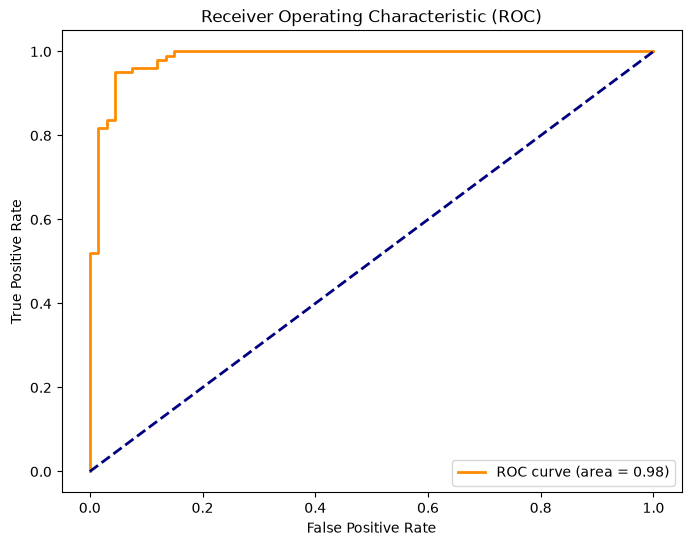

In [35]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr, tpr, color='darkorange', lw=2,
    label=f'ROC curve (area = {roc_auc:.2f})'
)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

**Verification against the book:** the ROC curve in Figure 7.11 gives an AUC of **98 %** — reproduced ✔ (0.984).

> **Book correction (definitions).** The book defines the true positive rate as "how frequently our model predicts the positive class". It is the **fraction of actual positives that are correctly identified** ($TPR=\frac{TP}{TP+FN}$, i.e. recall), and the false positive rate is the fraction of actual *negatives* wrongly flagged as positive ($\frac{FP}{FP+TN}$).
> "How frequently the model predicts positive" is a different quantity (the predicted-positive rate). The plotted line is orange, not "yellow".

### How it works…
* **Accuracy, precision, recall, F1** — as in Chapters 4 and 6 (precision $=TP/(TP+FP)$, recall $=TP/(TP+FN)$, F1 the harmonic mean).
* **ROC curve** — TPR against FPR across all decision thresholds; **AUC** — the single-number summary of how well the model separates the classes (0.5 random, 1 perfect).

**Extension — what does an SVM's "probability" mean, and is it needed for the ROC?** An SVM natively produces a **score**, `decision_function(x)` (signed distance to the hyperplane, up to a scale), not a probability. `probability=True` fits a *Platt scaling* sigmoid on top of it using an internal 5-fold
cross-validation (which makes `fit` slower — about 2× here, up to 5× in general). A **ROC curve only needs the ranking of the scores**, so `decision_function` gives the same AUC without any of that cost:

In [36]:
import time
scores = svm_model.decision_function(X_test)
fpr_s, tpr_s, _ = roc_curve(y_test, scores)
print(f"AUC from predict_proba      : {roc_auc:.4f}")
print(f"AUC from decision_function  : {auc(fpr_s, tpr_s):.4f}   (same ranking, no probability model needed)")
print("predict() agrees with predict_proba > 0.5 on", f"{((y_prob > .5).astype(int) == y_pred).mean():.1%}", "of the test points here (they can disagree on others, because Platt scaling is fitted separately)")

t0 = time.time(); SVC(kernel="linear").fit(X_train, y_train); t_plain = time.time() - t0
with warnings.catch_warnings():
    warnings.simplefilter("ignore"); t0 = time.time(); SVC(kernel="linear", probability=True).fit(X_train, y_train); t_prob = time.time() - t0
print(f"fit time without probability: {t_plain:.2f}s | with probability=True: {t_prob:.2f}s")

AUC from predict_proba      : 0.9841
AUC from decision_function  : 0.9841   (same ranking, no probability model needed)
predict() agrees with predict_proba > 0.5 on 99.4% of the test points here (they can disagree on others, because Platt scaling is fitted separately)


fit time without probability: 2.90s | with probability=True: 8.68s


**Extension — the modern way to get calibrated probabilities, and the effect of scaling.** `CalibratedClassifierCV` wraps any classifier; and standardising the features (Chapter 2) makes the linear SVM both faster and as accurate:

In [37]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss

models = {
    "SVC(probability=True), unscaled (book)": None,
    "CalibratedClassifierCV(SVC linear), unscaled": CalibratedClassifierCV(SVC(kernel="linear"), ensemble=False, cv=5),
    "scaled SVC(linear) + calibration": make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(kernel="linear"), ensemble=False, cv=5)),
    "scaled SVC(rbf) + calibration": make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(kernel="rbf"), ensemble=False, cv=5)),
}
rows = []
for name, m in models.items():
    t0 = time.time()
    if m is None:
        p_hat, pr_hat = y_pred, y_prob; t = np.nan
    else:
        m.fit(X_train, y_train); t = time.time() - t0; p_hat, pr_hat = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    f, t_, _ = roc_curve(y_test, pr_hat)
    rows.append({"model": name, "accuracy": accuracy_score(y_test, p_hat), "AUC": auc(f, t_), "Brier score (lower = better calibrated)": brier_score_loss(y_test, pr_hat), "fit time (s)": t})
pd.DataFrame(rows).set_index("model").round(3)

,accuracy,AUC,Brier score (lower = better calibrated),fit time (s)
model,,,,
"SVC(probability=True), unscaled (book)",0.947,0.984,0.042,NaN
"CalibratedClassifierCV(SVC linear), unscaled",0.947,0.984,0.043,6.756
scaled SVC(linear) + calibration,0.988,0.999,0.018,0.026
scaled SVC(rbf) + calibration,0.982,0.999,0.017,0.032


The calibrated *unscaled* linear SVM is identical to the book's version (accuracy 0.947, AUC 0.984, Brier 0.043; fit ≈ 6 s). **Standardising helps enormously on this dataset**: accuracy rises to 0.988 (linear) / 0.982 (RBF), AUC to 0.999, the Brier score falls from 0.043 to ≈ 0.018 (much better probabilities)
and the fit time drops from seconds to ≈ 0.03 s. This is the *opposite* of what happened on Iris and on the wide synthetic data above: the breast-cancer features are on wildly different scales (`area` in the hundreds, `smoothness` ≈ 0.1) *without* the scale being informative, so standardising removes a handicap
instead of a signal. **Whether to scale is an empirical question** — compare with and without, inside cross-validation.

### Visualizing model performance / There's more… (book)
The ROC curve shows the trade-off between the true-positive and false-positive rate; the AUC a threshold-free summary. The choice of metric depends on the task: if false positives are costly, precision matters more; if capturing every positive matters, recall (as in Chapter 6's cancer-screening discussion).

### Theory
* **SVM output = score.** $f(x)=w^\top x+b$ (or the kernel expansion); $|f|/\lVert w\rVert$ is the geometric distance to the hyperplane. Probabilities are an add-on (Platt scaling: $P(y=1\mid f)=1/(1+e^{Af+B})$).
* **ROC/AUC use ranks:** any monotonic transformation of the scores leaves the AUC unchanged, which is why `decision_function` is enough; *calibration* (do predicted 0.8 mean 80 %?) is a separate question assessed with calibration curves and the Brier score.
* **Imbalanced data:** AUC can look optimistic, precision–recall curves are more informative (Chapter 4); `SVC(class_weight='balanced')` re-weights `C` per class.

### Hands-on workflow (from the book)
Load Breast Cancer → `SVC` → fit → `predict` → accuracy, precision, recall, F1, ROC AUC → plot the ROC curve (done above, plus the score-vs-probability comparison).

## 6. Practical exercises with SVMs

The book gives three exercises as step lists. Here is my implementation of each.

### Exercise 1 — Build a simple SVM classifier (Iris)
Steps: libraries → data → split → create and train an SVM → predict → evaluate. (With a stratified split and standardisation, as good practice.)

accuracy: 0.9333 | support vectors per class: [ 7 17 16]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.93      0.87      0.90        15
   virginica       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



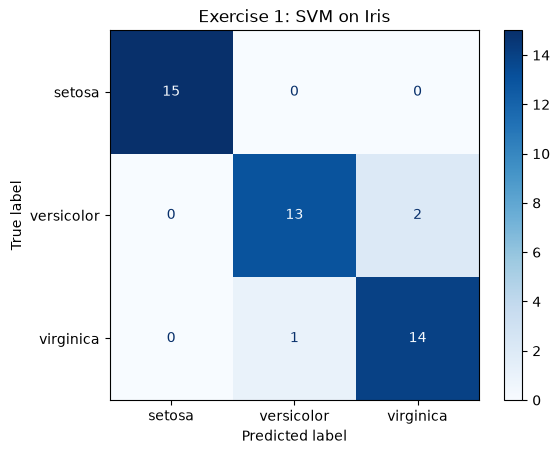

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay

Xi, yi = load_iris(return_X_y=True)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, random_state=2024, stratify=yi)

simple_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0)).fit(Xi_tr, yi_tr)
pred = simple_svm.predict(Xi_te)
print("accuracy:", round(accuracy_score(yi_te, pred), 4), "| support vectors per class:", simple_svm[-1].n_support_)
print(classification_report(yi_te, pred, target_names=load_iris().target_names))
ConfusionMatrixDisplay.from_predictions(yi_te, pred, display_labels=load_iris().target_names, cmap="Blues"); plt.title("Exercise 1: SVM on Iris"); plt.show()

### Exercise 2 — Tune an SVM with grid search (Breast Cancer)
Steps: libraries → data → split → define the grid → grid search with CV → train with the best parameters → predict → evaluate. A list of grids with the scaler inside the pipeline:

In [39]:
Xb, yb = load_breast_cancer(return_X_y=True)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=2024, stratify=yb)

pipe = Pipeline([("scale", StandardScaler()), ("svc", SVC())])
grids = [
    {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1, 1, 10]},
    {"svc__kernel": ["rbf"], "svc__C": [0.1, 1, 10, 100], "svc__gamma": [1e-4, 1e-3, 1e-2, 0.1]},
    {"svc__kernel": ["poly"], "svc__C": [0.1, 1, 10], "svc__degree": [2, 3]},
]
gs = GridSearchCV(pipe, grids, cv=5, scoring="accuracy").fit(Xb_tr, yb_tr)
best = gs.best_estimator_
pred = best.predict(Xb_te)
print("best parameters:", gs.best_params_)
print(f"CV accuracy {gs.best_score_:.4f} | test accuracy {accuracy_score(yb_te, pred):.4f}")
print(classification_report(yb_te, pred, target_names=load_breast_cancer().target_names))
print("untuned default SVC (no scaling) test accuracy for comparison:", round(SVC().fit(Xb_tr, yb_tr).score(Xb_te, yb_te), 4))

best parameters: {'svc__C': 0.1, 'svc__kernel': 'linear'}
CV accuracy 0.9799 | test accuracy 0.9708
              precision    recall  f1-score   support

   malignant       0.97      0.95      0.96        64
      benign       0.97      0.98      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171

untuned default SVC (no scaling) test accuracy for comparison: 0.9357


Tuning and scaling together lift the test accuracy from the unscaled default (0.936) to 0.971 (CV 0.980); a linear kernel with `C=0.1` wins, so on this dataset the extra flexibility of RBF/polynomial kernels is not needed. The malignant-class recall (the clinically important number, as in Chapter 6) is in the report above. As always, a difference of one or two of the 171 test samples is within noise; the CV score is the better guide.

### Exercise 3 — Visualise SVM decision boundaries (synthetic data)
Steps: libraries → synthetic binary dataset → split → train → mesh grid → "predict class probabilities across the grid" → plot. (`SVC` has no probabilities by default, so the **decision function** — the signed distance to the boundary — is evaluated on the grid; its zero contour is the decision boundary and ±1 are the margins.)

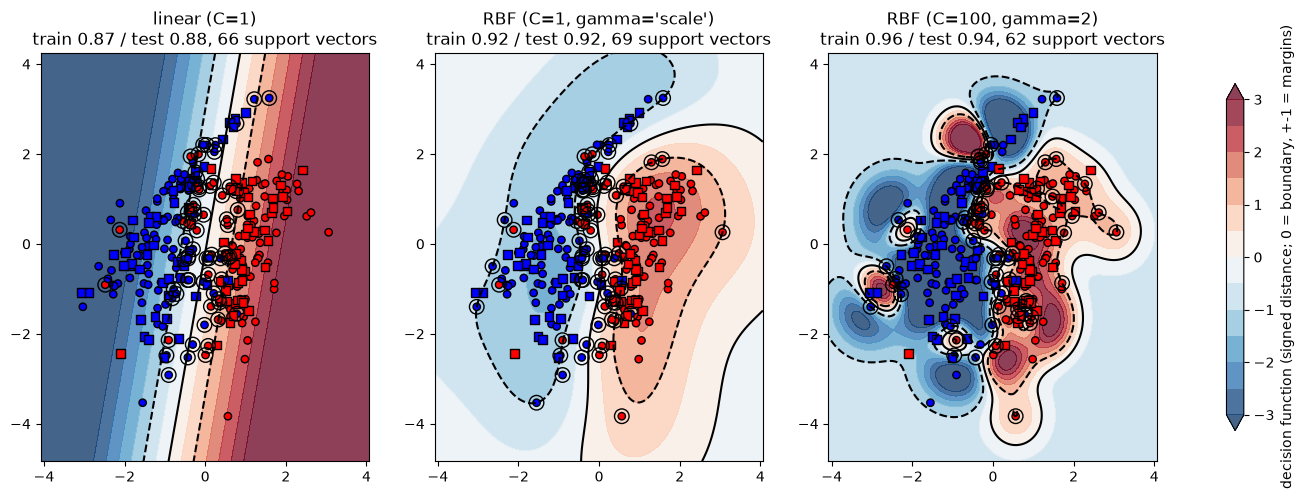

In [40]:
from sklearn.datasets import make_classification

Xs, ys = make_classification(n_samples=300, n_features=2, n_redundant=0, n_informative=2, n_clusters_per_class=2, class_sep=0.9, flip_y=0.04, random_state=2024)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=2024)

gx, gy = np.meshgrid(np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 300), np.linspace(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1, 300))
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
for ax, (name, model) in zip(axes, {"linear (C=1)": SVC(kernel="linear", C=1), "RBF (C=1, gamma='scale')": SVC(kernel="rbf", C=1), "RBF (C=100, gamma=2)": SVC(kernel="rbf", C=100, gamma=2)}.items()):
    model.fit(Xs_tr, ys_tr)
    Z = model.decision_function(grid).reshape(gx.shape)                         # signed distance to the boundary on every grid point
    cs = ax.contourf(gx, gy, Z, levels=np.linspace(-3, 3, 13), cmap="RdBu_r", alpha=.75, extend="both")
    ax.contour(gx, gy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(Xs_tr[:, 0], Xs_tr[:, 1], c=ys_tr, cmap="bwr", edgecolor="k", s=28)
    ax.scatter(Xs_te[:, 0], Xs_te[:, 1], c=ys_te, cmap="bwr", edgecolor="k", marker="s", s=38)
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=110, facecolors="none", edgecolors="k", linewidths=1)
    ax.set_title(f"{name}\ntrain {model.score(Xs_tr, ys_tr):.2f} / test {model.score(Xs_te, ys_te):.2f}, {model.n_support_.sum()} support vectors")
fig.colorbar(cs, ax=axes, label="decision function (signed distance; 0 = boundary, +-1 = margins)", shrink=.85)
plt.show()

Circles = training points, squares = test points, ringed points = support vectors; the solid black line is the decision boundary and the dashed lines the margins. The **linear** SVM draws a straight line through a dataset with two clusters per class, so it cannot be right;
the **RBF** SVM bends around the clusters (train 0.92 / test 0.92); the last model (large `C`, large `gamma`) wraps tightly around individual points, producing isolated "islands" (train 0.96 / test 0.94). Its test accuracy is actually the *best* of the three here, but the difference from the default RBF is
2 of 90 test points, i.e. noise, so the jagged shape is a warning sign rather than a verdict — only cross-validation (and a bigger test set) can tell whether such a flexible boundary generalises. (Note it has the *fewest* support vectors, 62: a large `C` tolerates few margin violations, whereas a large
`gamma` at fixed `C` makes almost every point a support vector, as in the moons example.) This single picture summarises the chapter's trade-offs.

### Theory (for the exercises)
* **Pipelines with scaling** are essential for SVMs; **tune on the training set by CV**, evaluate on the test set once.
* **Reading an SVM plot:** the zero level set is the boundary, the ±1 level sets the margins, support vectors are the points on or inside the margins; the number of support vectors is a complexity indicator — a very large `gamma` makes nearly every point a support vector (moons, `gamma=100`: 254 of 280), while a large `C` tends to *reduce* it (fewer margin violations tolerated), so read it together with the train–test gap.
* **Probabilities** are optional extras for SVMs (`probability=True` or `CalibratedClassifierCV`); the signed distance is often all you need.

## Chapter takeaways
1. An **SVM** finds the **maximum-margin hyperplane**; only the **support vectors** define it. A hyperplane is *flat* — curved boundaries in the original space come from **kernels**.
2. The **kernel trick** computes dot products in a (possibly infinite-dimensional) feature space without building it. **Linear** = no mapping; **polynomial** = interactions up to degree *d*; **RBF** = local similarity controlled by `gamma`.
3. **`C`** trades margin width against training errors; **`gamma`** (RBF) and **`degree`** (polynomial) set the boundary's flexibility. Large `C` and large `gamma` overfit; search both on a log scale, with any scaler **inside** a pipeline.
4. Differences between kernels on a **45-sample** test set (one sample per step) are noise — use cross-validation. On Iris the kernels are statistically tied.
5. **Scaling usually helps SVMs — but not always.** It helped hugely on breast cancer (0.947 → 0.988, fit time seconds → milliseconds) but *hurt* on Iris (slightly) and on the wide synthetic data (0.88 → 0.65), where the feature scale itself carried the signal. Compare with and without, inside cross-validation.
6. On **wide data**, defaults overfit (train accuracy 1.0, test 0.75). What worked: a non-linear kernel (0.88), L1 regularisation (0.83 linear), and especially **dimensionality reduction inside the pipeline** — `PCA(50)` → RBF reached 0.95 — while a 2-D PCA picture (≈ 5 % of the variance) said little about separability.
7. SVMs output **scores**, not probabilities; the ROC/AUC only needs the ranking (`decision_function`). `probability=True` is deprecated — use `CalibratedClassifierCV` when you need calibrated probabilities.

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| Hyperplane | "a non-linear line (a curved line)" | a hyperplane is flat; curvature comes from kernels |
| Boundary plot (Fig 7.2) | presented as an SVM classifier's non-linear boundary, "darker = more certain" | the model plotted is `SVR`; colours are the regression's predicted value, no class regions or certainty |
| `SVR` demo | MSE 0.20 on class labels | only a mechanical API demo (class ids are not a numeric scale) |
| Kernel descriptions | linear kernel "maps data linearly into a higher-dimensional space" | linear kernel is the identity (no mapping); RBF maps to an infinite-dimensional space |
| Kernel ranking | polynomial "better" and RBF "worst" on one split → inferences about data structure | one test sample per step (43/42/41 of 45); CV shows no reliable ranking |
| Grid search | `degree` in the grid for all kernels; reports `poly, degree 4, C=0.1` as "best" | `degree` is irrelevant for linear/rbf (12 duplicate fits); 8 configurations tie at the top; `gamma` never tuned |
| `C` plot | "plateaus around C = 10¹" | peaks near C ≈ 3 and then declines slightly |
| High-dim recipe | defaults perform poorly (0.747), "good that we know how to address these" | never addressed in the book. Regularisation (0.77), L1 (0.83), RBF (0.88) and unscaled `PCA(50)` → RBF (0.95) do; standardising hurts here (0.65) because feature scale carries the signal |
| High-dim PCA picture | "very challenging for a standard linear classifier" from the 2-D PCA plot | the 2 plotted components hold only 4.6 % of the variance; 50 components (52 %) give the best classifier |
| Kernel comparison (Iris) | scaling is implied to help (as a general rule) | on Iris standardising slightly *hurts* (linear 0.979 → 0.965; poly 0.967 → 0.924); on breast cancer it helps a lot (0.947 → 0.988) |
| Evaluation recipe code | `print(accuracy)` with `accuracy` undefined; `SVC(probability=True)` | `NameError` as printed (add `accuracy_score`); `probability` deprecated since scikit-learn 1.9 |
| ROC description | TPR = "how frequently our model predicts the positive class" | TPR = TP / (TP + FN), the share of actual positives found |
| Exercise 3 wording | "predict class probabilities across the grid" | `SVC` has no probabilities by default; use `decision_function` |
| Imports | `numpy`, `matplotlib`, `accuracy_score` missing in some snippets | added |

*Next: Chapter 8 — Tree-Based Algorithms and Ensemble Methods.*